In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def convert_to_rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [3]:
captures = cv2.VideoCapture(r'D:\Computer-Vision\Data\vtest.avi')

In [4]:
ret, frame = captures.read()

In [5]:
captures.get(cv2.CAP_PROP_FRAME_COUNT)
# بتجيب كام فريم موجود في الفيديو

795.0

In [6]:
random_frames = captures.get(cv2.CAP_PROP_FRAME_COUNT) * np.random.uniform(size = 30)

In [7]:
random_frames

array([607.65248804, 192.61164639, 517.69453008, 592.11913732,
       113.16041073, 399.49332819, 258.97666277, 522.07308196,
        61.97335449,  31.37473618, 184.31793696, 500.00968861,
       762.91408042, 239.52400319, 640.27497331,  65.07299446,
       631.24172084, 669.72804895,  52.110113  ,  95.21789556,
       778.98961998, 659.86813047, 121.67590076, 740.15883291,
       616.81252946, 201.27147126, 391.83932086, 357.57647437,
       443.68137623, 225.93141957])

In [8]:
frames = []

for frame_id in random_frames:
    captures.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ret, frame = captures.read()
    frames.append(frame)

captures.release()

# set بتستخدم لتغيير خاصية معينة في الفيديو. 
#  #cv2.CAP_PROP_POS_FRAMES دي الخاصية اللي بتحدد رقم الفريم اللي الكاميرا أو الفيديو واقف عنده

In [9]:
frames

[array([[[103, 139, 174],
         [104, 140, 175],
         [107, 143, 178],
         ...,
         [ 59,  84, 110],
         [ 68,  81, 102],
         [ 38,  51,  72]],
 
        [[103, 139, 174],
         [104, 140, 175],
         [106, 142, 177],
         ...,
         [ 59,  84, 110],
         [ 66,  79, 100],
         [ 42,  55,  76]],
 
        [[104, 140, 175],
         [106, 142, 177],
         [107, 143, 178],
         ...,
         [ 59,  84, 110],
         [ 74,  87, 108],
         [ 42,  55,  76]],
 
        ...,
 
        [[  0,  32,  18],
         [  0,  33,  19],
         [  0,  34,  20],
         ...,
         [ 19,  75,  64],
         [ 19,  75,  64],
         [ 20,  76,  65]],
 
        [[  0,  32,  18],
         [  0,  35,  21],
         [  0,  38,  24],
         ...,
         [ 15,  71,  60],
         [ 15,  71,  60],
         [ 18,  74,  63]],
 
        [[  0,  33,  19],
         [  0,  36,  22],
         [  0,  40,  26],
         ...,
         [ 19,  75,  64],
  

In [10]:
len(frames)

30

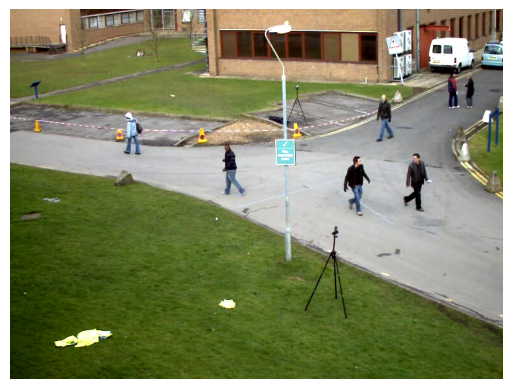

In [11]:
plt.imshow(convert_to_rgb(frames[10]))
plt.axis('off')
plt.show()

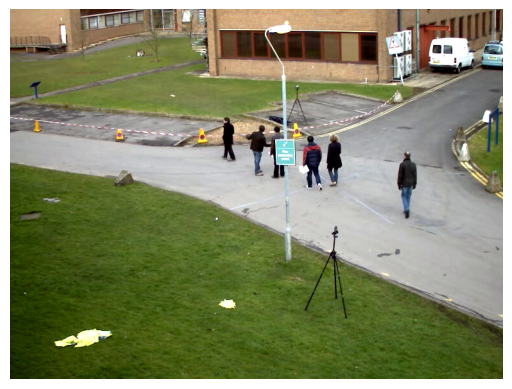

In [12]:
plt.imshow(convert_to_rgb(frames[15]))
plt.axis('off')
plt.show()  

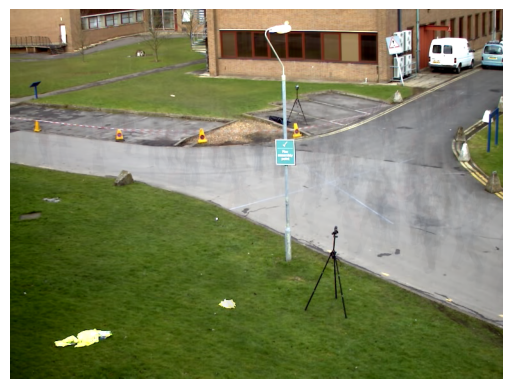

In [13]:
avg_frame = np.average(frames,axis=0).astype(np.uint8)

plt.imshow(convert_to_rgb(avg_frame))
plt.axis('off')
plt.show()

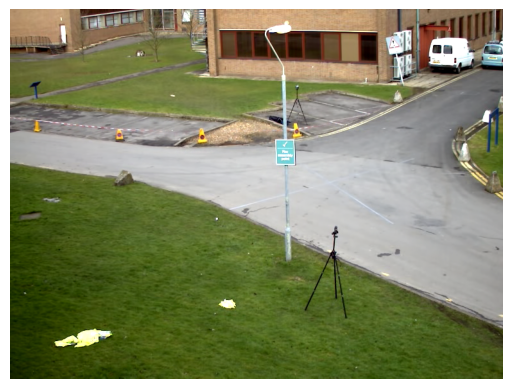

In [14]:
median_frame = np.median(frames,axis=0).astype(np.uint8)
plt.imshow(convert_to_rgb(median_frame))
plt.axis('off')
plt.show()

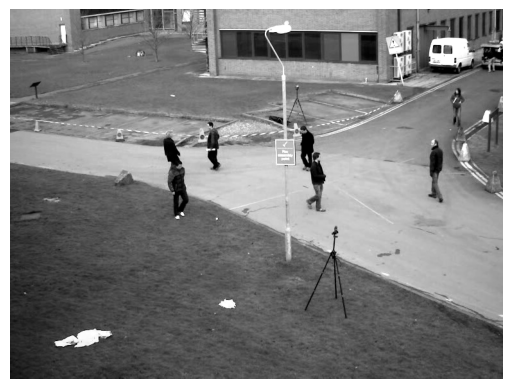

In [15]:
framex = frames[12]

gray_frame = cv2.cvtColor(framex, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_frame, cmap='gray')
plt.axis('off')
plt.show()

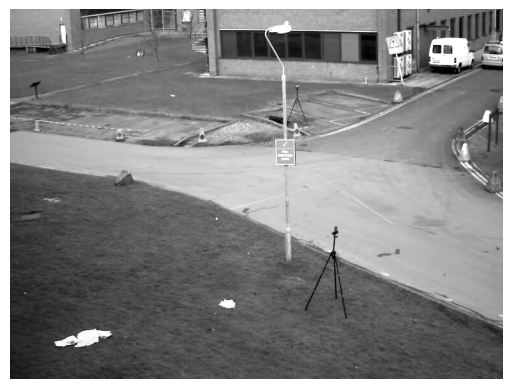

In [16]:
median_frame = np.median(frames,axis=0).astype(np.uint8)

gray_background = cv2.cvtColor(median_frame, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_background, cmap='gray')
plt.axis('off')
plt.show()

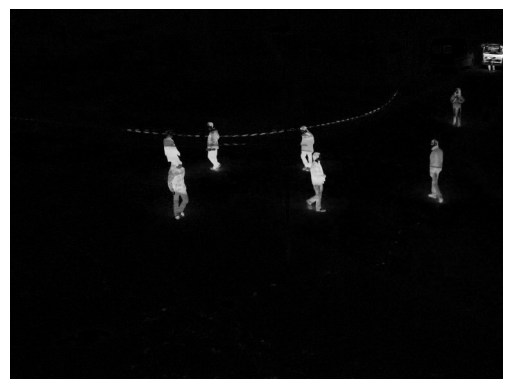

In [17]:
background_remove = cv2.absdiff(gray_background, gray_frame) # بتقارن الصورتين وتحسب الفرق بين كل بيكسل والتاني.
plt.imshow(background_remove, cmap='gray')
plt.axis('off')
plt.show()

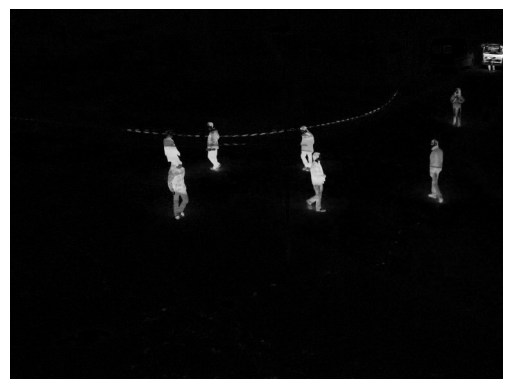

In [18]:
background_remove = cv2.absdiff(gray_background, gray_frame) 
plt.imshow(background_remove, cmap='gray')
plt.axis('off')
plt.show()

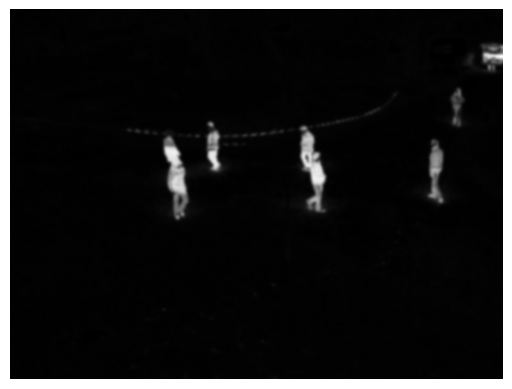

In [19]:
background_remove_blur = cv2.GaussianBlur(background_remove, (11,11), 0)

plt.imshow(background_remove_blur, cmap='gray')
plt.axis('off')
plt.show()

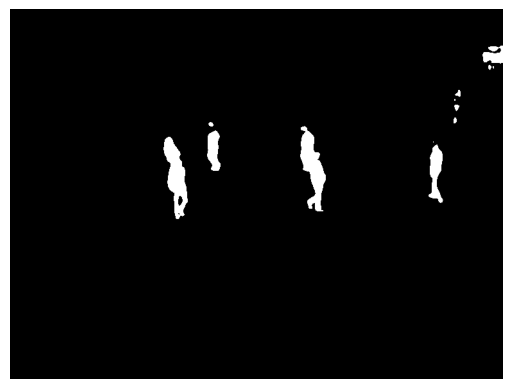

In [20]:
_,frametr = cv2.threshold(background_remove_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU) # مهم 

# cv2.THRESH_BINARY
#بتحول الصورة إلى لونين:
# أبيض (255): البكسلات اللي قيمتها أكبر من Threshold.
#أسود (0): البكسلات اللي قيمتها أقل من أو تساويه.

# cv2.THRESH_OTSU
#بتختار قيمة Threshold تلقائيًا بناءً على توزيع درجات الإضاءة في الصورة.

plt.imshow(frametr, cmap='gray')
plt.axis('off')
plt.show()

In [21]:
(countours, _) = cv2.findContours(frametr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

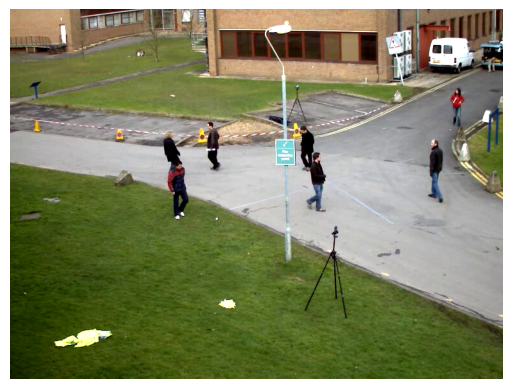

In [22]:
plt.imshow(convert_to_rgb(framex))
plt.axis('off')
plt.show()  

In [23]:
fff = cv2.cvtColor(frametr, cv2.COLOR_GRAY2BGR)
for co in countours:
    x,y,w,h = cv2.boundingRect(co)
    cv2.rectangle(fff,(x,y),(x+w,y+h),(0,255,0),2)

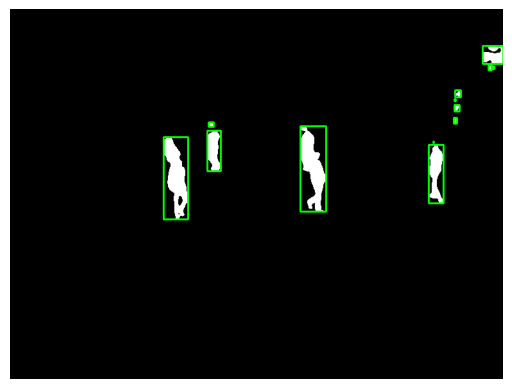

In [24]:
plt.imshow(fff)
plt.axis('off')
plt.show()  

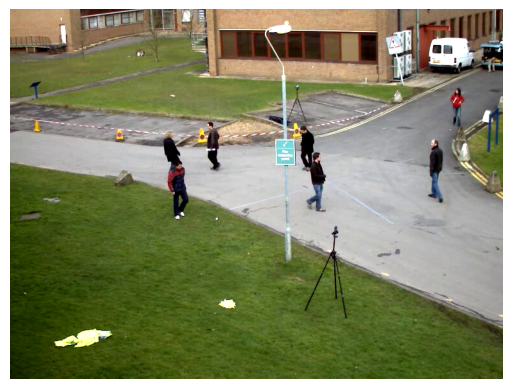

In [25]:
plt.imshow(convert_to_rgb(framex))
plt.axis('off')
plt.show()  

In [26]:
background_subtract = cv2.createBackgroundSubtractorMOG2()  # إنشاء Background Subtractor لفصل الخلفية عن الأجسام المتحركة

captures = cv2.VideoCapture(r'D:\Computer-Vision\Data\background video _ people _ walking _.mp4')  # فتح الفيديو

while captures.isOpened():  # التأكد إن الفيديو مفتوح

    ret, frame = captures.read()  # قراءة Frame من الفيديو

    if not ret:  # التأكد إن قراءة الفريم نجحت
        break  # إيقاف الحلقة لو مفيش فريمات تاني

    fg_mask = background_subtract.apply(frame)  # فصل الأجسام المتحركة عن الخلفية وإنشاء Foreground Mask

    (countours, _) = cv2.findContours(fg_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # اكتشاف الحدود الخارجية للأجسام

    for co in countours:  # المرور على كل Contour تم اكتشافه

        if cv2.contourArea(co) > 500:  # تجاهل الأجسام الصغيرة اللي مساحتها 500 أو أقل

            x, y, w, h = cv2.boundingRect(co)  # تحديد مكان وأبعاد المستطيل المحيط بالجسم

            cv2.rectangle(frame, (x,y), (x+w,y+h), (0,255,0), 2)  # رسم مستطيل أخضر حول الجسم

    cv2.imshow('Foreground Mask', fg_mask)  # عرض صورة الأجسام المتحركة بعد فصلها عن الخلفية

    cv2.imshow('Tracked Objects', frame)  # عرض الفيديو مع المستطيلات حول الأجسام المكتشفة

    if cv2.waitKey(30) & 0xFF == ord('q'):  # انتظار 30 مللي ثانية والتحقق من ضغط زر Q
        break  # إيقاف تشغيل الفيديو عند الضغط على Q

captures.release()  # تحرير الفيديو وإغلاقه

cv2.destroyAllWindows()  # إغلاق جميع نوافذ OpenCV